# Entrenamiento — resultados y elección del modelo

Resultados de los entrenamientos en SageMaker y por qué el modelo en producción es el que es:

1. **Los tres entrenamientos completos** y su comparación con la misma regla de umbral.
2. **Curvas por época** (pérdida y kappa en validación) leídas de los logs de CloudWatch.
3. **El modelo final en prueba:** matriz de confusión, acierto por grado y accuracy.
4. **El umbral de referible:** cuánta sensibilidad se gana y cuánta especificidad se pierde.
5. **La confianza del modelo:** cuántas fotos van a revisión humana y qué tan bien acierta en las demás.
6. **Error por cámara:** si el modelo aprendió la cámara en lugar de la enfermedad (solo en Studio).

No entrena nada ni necesita GPU: lee lo que dejó `train.py` en `s3://<S3_BUCKET_MODELS>/models/<run_id>/`
(`metadata.json` y `predictions.csv`, contratos 4.3 y 4.7) y los logs de cada trabajo.

**Cómo se dividieron las fotos** (`data/splits.csv`, `notebooks/splits.ipynb`): de las 3,662 de APTOS se
quitaron los duplicados (quedan 3,466) y se dividieron 70/15/15 estratificado por grado y con semilla fija.
**Entrenamiento** (2,426) para aprender los pesos; **validación** (520) para escoger la mejor época, los umbrales
y el modelo; **prueba** (520) solo para reportar, sin tomar ninguna decisión con ella.

In [1]:
import io
import json
import os
import re
import sys
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, roc_curve

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

try:
    from dotenv import load_dotenv
    load_dotenv(REPO / ".env")
except ImportError:
    pass

from src.data.metrics import choose_thresholds, compute_metrics

BUCKET = os.environ["S3_BUCKET_MODELS"]
REGION = os.environ.get("AWS_REGION", "us-east-1")
s3 = boto3.client("s3", region_name=REGION)
logs = boto3.client("logs", region_name=REGION)

CLASS_NAMES = ["Sin retinopatía", "Leve", "Moderada", "Severa", "Proliferativa"]
COLORS = {"512": "#2e75b6", "regularizado": "#c55a11", "640": "#548235"}
plt.rcParams["figure.dpi"] = 90

# Los tres entrenamientos completos. Todos se comparan con la misma regla: umbral de referible escogido en
# validación con sensibilidad mínima 0.95. (A 2026-11-23-effb3-184323 después se le aplicó 0.96 con
# rethreshold.py; su versión con 0.95 quedó en metadata.before-rethreshold.json.)
RUNS = {
    "512": ("2026-11-23-effb3-162536", "metadata.json", "B3 a 512 px (en producción)"),
    "regularizado": ("2026-11-23-effb3-172449", "metadata.json", "B3 a 512 px, weight decay 0.05 + label smoothing 0.1"),
    "640": ("2026-11-23-effb3-184323", "metadata.before-rethreshold.json", "B3 a 640 px, batch 16"),
}
FINAL = "512"


def s3_bytes(key):
    with s3.get_object(Bucket=BUCKET, Key=key)["Body"] as body:
        return body.read()


def epoch_log(run_id):
    # Lee las líneas `epoch=… train_loss=… val_loss=… val_qwk=…` del log del trabajo bd-<run_id>
    group, job = "/aws/sagemaker/TrainingJobs", f"bd-{run_id}"
    rows = []
    for stream in logs.describe_log_streams(logGroupName=group, logStreamNamePrefix=job)["logStreams"]:
        token = None
        while True:
            kw = dict(logGroupName=group, logStreamName=stream["logStreamName"], startFromHead=True)
            if token:
                kw["nextToken"] = token
            page = logs.get_log_events(**kw)
            for e in page["events"]:
                if re.match(r"epoch=\d+ ", e["message"]):
                    rows.append({k: float(v) for k, v in re.findall(r"(\w+)=([0-9.]+)", e["message"])})
            if page["nextForwardToken"] == token:
                break
            token = page["nextForwardToken"]
    return pd.DataFrame(rows).drop_duplicates("epoch").sort_values("epoch").reset_index(drop=True)


meta, preds, epochs = {}, {}, {}
for name, (run_id, meta_file, _) in RUNS.items():
    meta[name] = json.loads(s3_bytes(f"models/{run_id}/{meta_file}"))
    preds[name] = pd.read_csv(io.BytesIO(s3_bytes(f"models/{run_id}/predictions.csv")))
    epochs[name] = epoch_log(run_id)

current = json.loads(s3_bytes("models/current/promoted_from.json"))
print("En producción (models/current/):", current["run_id"])
{name: (m["run_id"], m["image_size"], len(preds[name]), len(epochs[name])) for name, m in meta.items()}

En producción (models/current/): 2026-11-23-effb3-162536


{'512': ('2026-11-23-effb3-162536', 512, 1040, 20),
 'regularizado': ('2026-11-23-effb3-172449', 512, 1040, 20),
 '640': ('2026-11-23-effb3-184323', 640, 1040, 20)}

## 1. Los tres entrenamientos

Los tres usan EfficientNet-B3 con pesos Noisy Student, 20 épocas, AdamW con lr 3e-4 y pesos por clase, en
`ml.g5.xlarge`. Lo que cambia:

- **512:** la configuración base.
- **Regularizado:** weight decay 0.05 (antes 1e-4) y label smoothing 0.1, para atacar el sobreajuste del primero.
- **640:** la misma configuración base con fotos de 640 px (batch 16, porque a 32 no cabe en la GPU).

El modelo se escoge con el **kappa en validación**; las métricas de **prueba** son las que se reportan.

In [2]:
def p_matrix(df):
    return df[[f"p{c}" for c in range(5)]].to_numpy()


def summary_row(name):
    m, df = meta[name], preds[name]
    test = df[df.split == "test"]
    P, y = p_matrix(test), test.diagnosis.to_numpy()
    tr = m["training"]
    return {
        "modelo": name,
        "fotos (px)": m["image_size"],
        "batch": tr["batch_size"],
        "weight decay": tr["weight_decay"],
        "label smoothing": tr.get("label_smoothing", 0.0),
        "mejor época": tr["best_epoch"],
        "kappa val": m["validation_metrics"]["qwk"],
        "kappa prueba": m["metrics"]["qwk"],
        "accuracy prueba": (P.argmax(1) == y).mean(),
        "sensibilidad prueba": m["metrics"]["sensitivity_referable"],
        "especificidad prueba": m["metrics"]["specificity_referable"],
        "revisión humana": (P.max(1) < m["decision"]["confidence_threshold"]).mean(),
        "umbral referible": m["decision"]["referable_threshold"],
        "umbral confianza": m["decision"]["confidence_threshold"],
    }


summary = pd.DataFrame([summary_row(n) for n in RUNS]).set_index("modelo")
summary.style.format({c: "{:.3f}" for c in ["kappa val", "kappa prueba", "sensibilidad prueba", "especificidad prueba"]}
                     | {"accuracy prueba": "{:.1%}", "revisión humana": "{:.1%}", "weight decay": "{:g}", "label smoothing": "{:g}",
                        "umbral referible": "{:.2f}", "umbral confianza": "{:.2f}"}) \
    .highlight_max(subset=["kappa val"], color="#d9ead3")

,fotos (px),batch,weight decay,label smoothing,mejor época,kappa val,kappa prueba,accuracy prueba,sensibilidad prueba,especificidad prueba,revisión humana,umbral referible,umbral confianza
modelo,,,,,,,,,,,,,
512,512,32,0.0001,0,17,0.893,0.914,83.8%,0.931,0.950,14.4%,0.10,0.87
regularizado,512,32,0.05,0.1,11,0.884,0.905,81.9%,0.926,0.887,40.4%,0.33,0.66
640,640,16,0.0001,0,19,0.904,0.915,84.4%,0.896,0.953,14.8%,0.19,0.86


## 2. Curvas por época

Izquierda: pérdida de entrenamiento (línea continua) y de validación (punteada). Derecha: kappa en validación;
el punto marca la época que se guardó (la de mayor kappa).

Si la pérdida de entrenamiento baja mucho más que la de validación, el modelo está memorizando las fotos de
entrenamiento (sobreajuste). `train.py` se queda con la época de mejor kappa en validación, no con la última.

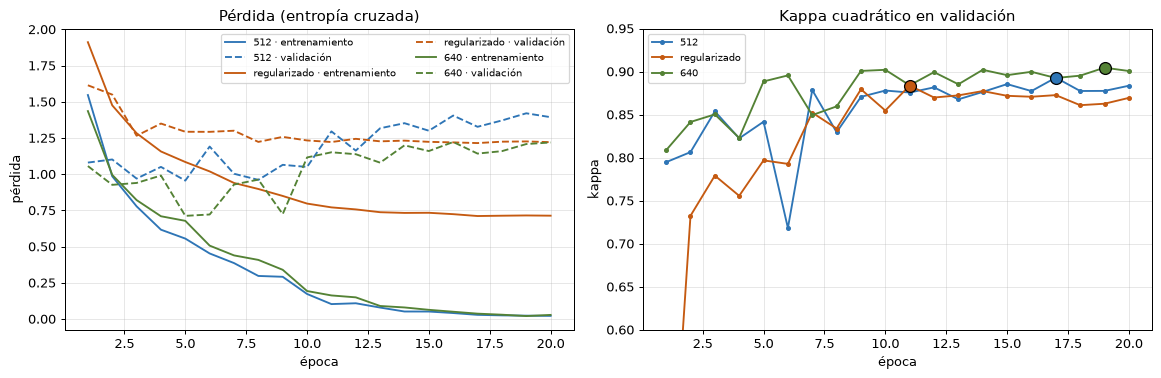

,512,regularizado,640
segundos por época,28.15,28.15,42.65
minutos (20 épocas),9.38,9.38,14.22
train_loss final,0.02,0.71,0.03
val_loss final,1.39,1.22,1.22


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for name, df in epochs.items():
    c = COLORS[name]
    axes[0].plot(df.epoch, df.train_loss, color=c, label=f"{name} · entrenamiento")
    axes[0].plot(df.epoch, df.val_loss, color=c, ls="--", label=f"{name} · validación")
    axes[1].plot(df.epoch, df.val_qwk, color=c, marker=".", label=name)
    best = meta[name]["training"]["best_epoch"]
    axes[1].scatter([best], [df.loc[df.epoch == best, "val_qwk"].iloc[0]], s=90, color=c, edgecolor="black", zorder=5)
axes[0].set(title="Pérdida (entropía cruzada)", xlabel="época", ylabel="pérdida")
axes[1].set(title="Kappa cuadrático en validación", xlabel="época", ylabel="kappa", ylim=(0.6, 0.95))
axes[0].legend(fontsize=8, ncol=2)
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({n: {"segundos por época": df.time.mean(), "minutos (20 épocas)": df.time.sum() / 60,
                  "train_loss final": df.train_loss.iloc[-1], "val_loss final": df.val_loss.iloc[-1]}
              for n, df in epochs.items()}).round(2)

## 3. El modelo final en prueba

Modelo en producción: **B3 a 512 px** (`2026-11-23-effb3-162536`). Matriz de confusión en las 520 fotos de
prueba: filas = grado real, columnas = grado que predijo el modelo (el más probable). A la derecha, la misma
matriz en porcentaje de cada fila.

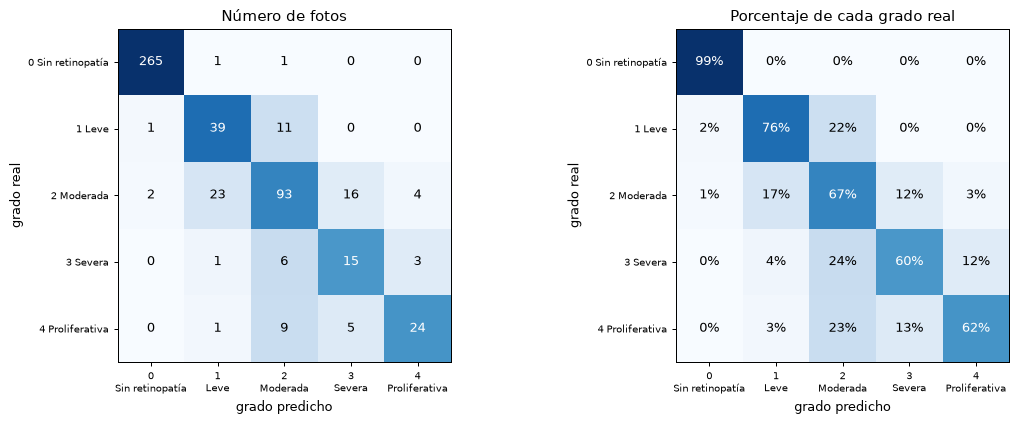

Accuracy (grado exacto): 83.8% · a 1 grado o menos: 96.5% · kappa cuadrático: 0.914


,fotos,aciertos,acierto,se confunde más con
Sin retinopatía,267,265,99.3%,Leve
Leve,51,39,76.5%,Moderada
Moderada,138,93,67.4%,Leve
Severa,25,15,60.0%,Moderada
Proliferativa,39,24,61.5%,Moderada


In [4]:
test = preds[FINAL][preds[FINAL].split == "test"]
P, y = p_matrix(test), test.diagnosis.to_numpy()
pred = P.argmax(1)
cm = np.array(meta[FINAL]["metrics"]["confusion_matrix"])
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, mat, fmt, title in [(axes[0], cm, "d", "Número de fotos"), (axes[1], cm_pct, ".0%", "Porcentaje de cada grado real")]:
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=10)
    ax.set_xticks(range(5), [f"{i}\n{n}" for i, n in enumerate(CLASS_NAMES)], fontsize=8)
    ax.set_yticks(range(5), [f"{i} {n}" for i, n in enumerate(CLASS_NAMES)], fontsize=8)
    ax.set(xlabel="grado predicho", ylabel="grado real", title=title)
plt.tight_layout()
plt.show()

per_class = pd.DataFrame({
    "fotos": cm.sum(axis=1),
    "aciertos": np.diag(cm),
    "acierto": np.diag(cm) / cm.sum(axis=1),
    "se confunde más con": [CLASS_NAMES[int(np.argmax(np.where(np.arange(5) == i, -1, cm[i])))] for i in range(5)],
}, index=CLASS_NAMES)
print(f"Accuracy (grado exacto): {(pred == y).mean():.1%} · a 1 grado o menos: {(abs(pred - y) <= 1).mean():.1%} · "
      f"kappa cuadrático: {cohen_kappa_score(y, pred, weights='quadratic'):.3f}")
per_class.style.format({"acierto": "{:.1%}"})

## 4. El umbral de referible

La API decide si un caso es **referible** (amarillo o rojo) cuando P(grado ≥ 2) pasa el umbral. Con un umbral
bajo se refiere a más gente: sube la **sensibilidad** (menos pacientes con retinopatía se van a casa) y baja la
**especificidad** (más pacientes sanos referidos de más). Para un tamizaje, el error caro es el primero.

El umbral se escoge **en validación** (el de mayor especificidad que cumpla una sensibilidad mínima) y se mide
**en prueba**. La primera versión pedía 0.90; se cambió a 0.95 (`rethreshold.py`, sin reentrenar).

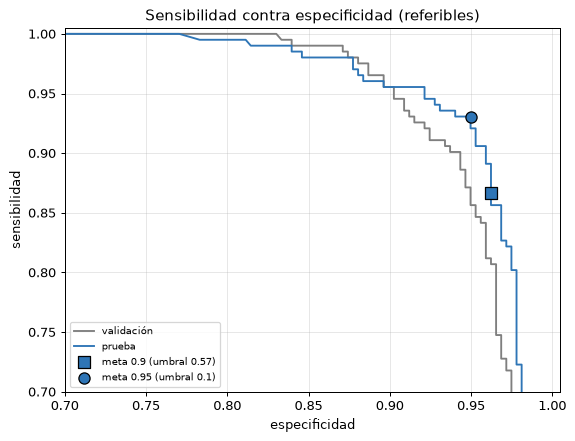

,umbral,sensibilidad prueba,especificidad prueba,referibles que se escapan,sanos referidos de más
meta en validación,,,,,
0.85,0.83,0.807,0.975,39,8
0.90,0.57,0.866,0.962,27,12
0.93,0.16,0.916,0.953,17,15
0.95,0.10,0.931,0.950,14,16
0.97,0.02,0.950,0.921,10,25


In [5]:
val = preds[FINAL][preds[FINAL].split == "val"]
Pv, yv = p_matrix(val), val.diagnosis.to_numpy()
rows = []
for target in [0.85, 0.90, 0.93, 0.95, 0.97]:
    t = choose_thresholds(yv, Pv, min_sensitivity=target)["referable_threshold"]
    mt = compute_metrics(y, P, t)
    referable, healthy = (y >= 2).sum(), (y < 2).sum()
    rows.append({"meta en validación": target, "umbral": round(float(t), 2),
                 "sensibilidad prueba": mt["sensitivity_referable"], "especificidad prueba": mt["specificity_referable"],
                 "referibles que se escapan": round(referable * (1 - mt["sensitivity_referable"])),
                 "sanos referidos de más": round(healthy * (1 - mt["specificity_referable"]))})
tradeoff = pd.DataFrame(rows).set_index("meta en validación")

fig, ax = plt.subplots(figsize=(6.5, 5))
for split, (yy, PP), c in [("validación", (yv, Pv), "#7f7f7f"), ("prueba", (y, P), COLORS[FINAL])]:
    fpr, tpr, _ = roc_curve(yy >= 2, PP[:, 2:].sum(1))
    ax.plot(1 - fpr, tpr, color=c, label=split)
for target, marker in [(0.90, "s"), (0.95, "o")]:
    r = tradeoff.loc[target]
    ax.scatter(r["especificidad prueba"], r["sensibilidad prueba"], marker=marker, s=80, color=COLORS[FINAL],
               edgecolor="black", zorder=5, label=f"meta {target} (umbral {r['umbral']})")
ax.set(xlabel="especificidad", ylabel="sensibilidad", title="Sensibilidad contra especificidad (referibles)",
       xlim=(0.7, 1.005), ylim=(0.7, 1.005))
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

tradeoff.style.format({"umbral": "{:.2f}", "sensibilidad prueba": "{:.3f}", "especificidad prueba": "{:.3f}"}).format_index("{:.2f}")

## 5. La confianza del modelo

Si la probabilidad del grado más probable queda debajo del **umbral de confianza** (escogido en validación para
que las fotos que sí reciben color acierten al menos el 90 %), la API no asigna color y manda la foto a revisión
humana.

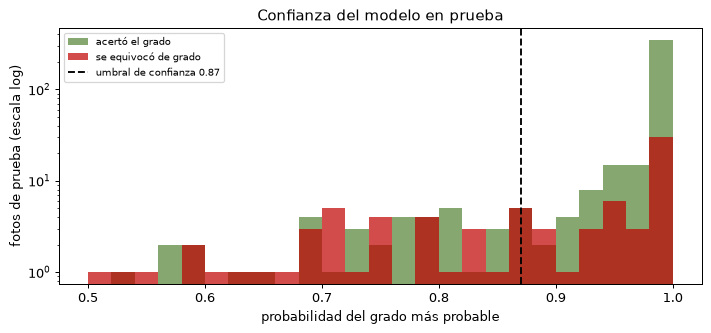

,umbral 0.87
fotos con color (confianza alta),445 (85.6%)
accuracy en esas fotos,89.4%
fotos a revisión humana,75 (14.4%)
accuracy en las de revisión humana,50.7%


In [6]:
conf_t = meta[FINAL]["decision"]["confidence_threshold"]
max_p = P.max(1)
confident = max_p >= conf_t

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0.5, 1, 26)
ax.hist(max_p[pred == y], bins=bins, alpha=0.7, color="#548235", label="acertó el grado")
ax.hist(max_p[pred != y], bins=bins, alpha=0.7, color="#c00000", label="se equivocó de grado")
ax.axvline(conf_t, color="black", ls="--", label=f"umbral de confianza {conf_t}")
ax.set_yscale("log")
ax.set(xlabel="probabilidad del grado más probable", ylabel="fotos de prueba (escala log)",
       title="Confianza del modelo en prueba")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.Series({
    "fotos con color (confianza alta)": f"{confident.sum()} ({confident.mean():.1%})",
    "accuracy en esas fotos": f"{(pred == y)[confident].mean():.1%}",
    "fotos a revisión humana": f"{(~confident).sum()} ({(~confident).mean():.1%})",
    "accuracy en las de revisión humana": f"{(pred == y)[~confident].mean():.1%}",
}, name=f"umbral {conf_t}").to_frame()

## 6. Error por cámara (ejecutar en Studio)

En el EDA vimos que la resolución de la foto (que identifica a la cámara) se relaciona casi por completo con la
clase en algunas cámaras. Si el modelo hubiera aprendido a reconocer la cámara en lugar de la enfermedad:

- le iría mucho mejor en las cámaras **de una sola clase** que en las **mezcladas**, y
- un predictor que **solo mira la cámara** (la clase más común de esa cámara en entrenamiento) se le acercaría.

Usa `DATA_DIR/image_stats.csv` (alto y ancho de cada foto original, del EDA), que solo está en Studio. Para tener
más fotos por cámara junta validación y prueba (1,040 fotos); la validación se usó para escoger época y umbrales,
así que sus números son un poco optimistas, pero sirven para comparar cámaras entre sí.

In [7]:
DATA_DIR = Path(os.environ.get("DATA_DIR", REPO / "data" / "aptos")).expanduser()
stats_path = DATA_DIR / "image_stats.csv"
if not stats_path.is_file():
    print("No existe DATA_DIR/image_stats.csv: esta sección se ejecuta en Studio, donde están las fotos originales.")
else:
    stats = pd.read_csv(stats_path)[["id_code", "height", "width"]]
    stats["cámara"] = stats.height.astype(int).astype(str) + "×" + stats.width.astype(int).astype(str)
    splits = pd.read_csv(REPO / "data" / "splits.csv").merge(stats, on="id_code")

    # Predictor que solo mira la cámara: la clase más común de esa cámara en entrenamiento
    train_part = splits[splits.split == "train"]
    camera_majority = train_part.groupby("cámara").diagnosis.agg(lambda s: s.value_counts().idxmax())
    camera_purity = train_part.groupby("cámara").diagnosis.agg(lambda s: s.value_counts(normalize=True).max())

    ev = preds[FINAL][preds[FINAL].split.isin(["val", "test"])].merge(stats, on="id_code")
    Pe = p_matrix(ev)
    thr = meta[FINAL]["decision"]["referable_threshold"]
    ev = ev.assign(pred=Pe.argmax(1), referable=ev.diagnosis >= 2, pred_referable=Pe[:, 2:].sum(1) >= thr,
                   solo_camara=ev["cámara"].map(camera_majority),
                   pureza=ev["cámara"].map(camera_purity))

    def camera_stats(g):
        ref, healthy = g.referable, ~g.referable
        return pd.Series({
            "fotos": len(g),
            "% referibles": ref.mean(),
            "accuracy modelo": (g.pred == g.diagnosis).mean(),
            "accuracy solo cámara": (g.solo_camara == g.diagnosis).mean(),
            "sensibilidad": (g.pred_referable & ref).sum() / ref.sum() if ref.any() else np.nan,
            "especificidad": (~g.pred_referable & healthy).sum() / healthy.sum() if healthy.any() else np.nan,
            "pureza en entrenamiento": g.pureza.iloc[0],
        })

    by_camera = ev.groupby("cámara").apply(camera_stats, include_groups=False).sort_values("fotos", ascending=False)
    pct = {c: "{:.0%}" for c in ["% referibles", "accuracy modelo", "accuracy solo cámara", "sensibilidad",
                                 "especificidad", "pureza en entrenamiento"]}
    display(by_camera.style.format(pct | {"fotos": "{:.0f}"}, na_rep="—"))

,fotos,% referibles,accuracy modelo,accuracy solo cámara,sensibilidad,especificidad,pureza en entrenamiento
cámara,,,,,,,
1050×1050,292,5%,97%,93%,87%,99%,93%
1736×2416,163,61%,66%,37%,93%,67%,39%
1958×2588,148,54%,74%,36%,90%,90%,47%
2136×3216,114,93%,77%,72%,99%,12%,77%
1536×2048,113,0%,100%,100%,—,100%,100%
614×819,90,0%,99%,98%,—,100%,97%
2588×3388,45,91%,56%,60%,93%,0%,67%
1226×1844,19,84%,84%,16%,100%,100%,38%
2848×4288,16,69%,69%,31%,100%,40%,36%


,fotos,kappa modelo,accuracy modelo,accuracy solo cámara
de una sola clase (≥ 90 %),497,0.902,98.2%,95.4%
mezclada,543,0.772,71.3%,47.3%
todas,1040,0.904,84.1%,70.3%


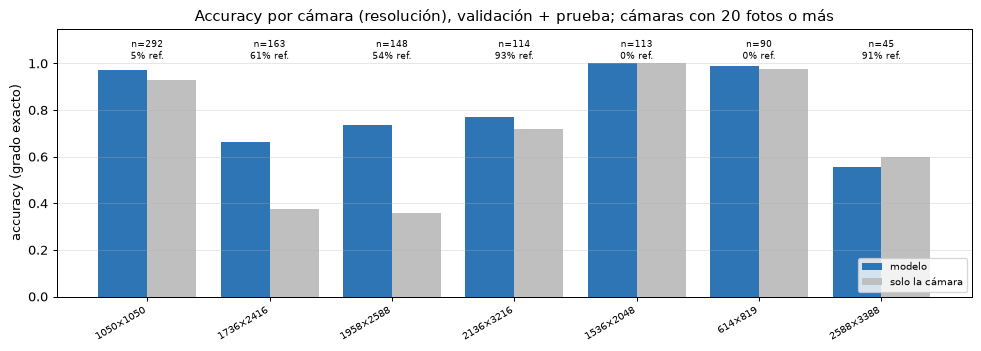

In [8]:
if stats_path.is_file():
    ev["tipo de cámara"] = np.where(ev.pureza >= 0.9, "de una sola clase (≥ 90 %)", "mezclada")
    by_type = ev.groupby("tipo de cámara").apply(lambda g: pd.Series({
        "fotos": len(g),
        "kappa modelo": cohen_kappa_score(g.diagnosis, g.pred, weights="quadratic"),
        "accuracy modelo": (g.pred == g.diagnosis).mean(),
        "accuracy solo cámara": (g.solo_camara == g.diagnosis).mean(),
    }), include_groups=False)
    overall = pd.Series({"fotos": len(ev),
                         "kappa modelo": cohen_kappa_score(ev.diagnosis, ev.pred, weights="quadratic"),
                         "accuracy modelo": (ev.pred == ev.diagnosis).mean(),
                         "accuracy solo cámara": (ev.solo_camara == ev.diagnosis).mean()}, name="todas")
    by_type = pd.concat([by_type, overall.to_frame().T])
    display(by_type.style.format({"fotos": "{:.0f}", "kappa modelo": "{:.3f}",
                                  "accuracy modelo": "{:.1%}", "accuracy solo cámara": "{:.1%}"}))

    big = by_camera[by_camera.fotos >= 20]
    fig, ax = plt.subplots(figsize=(11, 4))
    xs = np.arange(len(big))
    ax.bar(xs - 0.2, big["accuracy modelo"], 0.4, color=COLORS[FINAL], label="modelo")
    ax.bar(xs + 0.2, big["accuracy solo cámara"], 0.4, color="#bfbfbf", label="solo la cámara")
    for k, (cam, r) in enumerate(big.iterrows()):
        ax.text(k, 1.02, f"n={r.fotos:.0f}\n{r['% referibles']:.0%} ref.", ha="center", fontsize=7)
    ax.set_xticks(xs, big.index, rotation=30, ha="right", fontsize=8)
    ax.set(ylim=(0, 1.15), ylabel="accuracy (grado exacto)",
           title="Accuracy por cámara (resolución), validación + prueba; cámaras con 20 fotos o más")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

**Cómo leerlo:** si en las cámaras mezcladas el modelo acierta casi lo mismo que en las de una sola clase, y en
ambas supera claramente al predictor que solo mira la cámara, el modelo está usando la retina y no la cámara. Si
en las cámaras mezcladas cae mucho, o si "solo cámara" se le acerca, hay que reportarlo como riesgo (sección 10.3
del reporte).

## 7. Conclusiones

- **Modelo en producción: EfficientNet-B3 a 512 px** (`2026-11-23-effb3-162536`), con el umbral de referible
  escogido en validación con sensibilidad mínima 0.95. En prueba: **kappa 0.914**, **accuracy 83.8 %**
  (96.5 % a un grado o menos), **sensibilidad de referibles 0.931** y **especificidad 0.950**. Todo (época,
  umbrales y modelo) se decidió con validación, antes de ver la prueba.
- **Dónde se equivoca:** casi siempre entre grados vecinos. El error más común es moderada → leve (23 de 138
  moderadas), que es el que más importa porque deja en verde a alguien referible. Las fotos sin retinopatía casi
  nunca se refieren de más (265 de 267 bien) y ninguna severa o proliferativa salió como sin retinopatía.
- **Umbral:** pasar la meta de sensibilidad de 0.90 a 0.95 bajó los referibles que se escapan de 27 a 14 a cambio
  de 4 sanos referidos de más. Para un tamizaje es el intercambio correcto.
- **Sobreajuste:** la pérdida de entrenamiento baja a ~0.02, mientras que la de validación llega a su mínimo
  alrededor de la época 3–5 y luego sube; aun así el kappa en validación sigue mejorando hasta la época 17. Más
  regularización (weight decay 0.05 + label smoothing 0.1) no ayudó: bajó el kappa en validación (0.884) y dejó al
  modelo tan inseguro que el 40 % de las fotos iría a revisión humana.
- **Más resolución (640 px):** kappa en validación 0.904 y en prueba 0.915, prácticamente igual, pero con menos
  sensibilidad en prueba con la misma regla de umbral (0.896) y ~1.5 veces más lento. No justifica el cambio.
- **Confianza:** ~14 % de las fotos va a revisión humana; en las demás el modelo acierta el grado ~90 % de las
  veces.
- **Costo:** cada entrenamiento completo costó entre $0.32 y $0.44 en `ml.g5.xlarge` (sin Spot, porque ese día no
  había capacidad Spot).